# Notebook 1: Python basics and exercises

*Python for Instrumentation and Laboratory Experiments, Pr. T. Angot*

## Summary of the first class

- Python is free, open source and runs on Windows, macOS and Linux. We install it with Anaconda and work in Jupyter notebooks (`jupyter notebook`, `Shift+Enter` runs a cell).
- Useful libraries: `numpy` (arrays, maths), `matplotlib` (plots), `scipy` (fits, integration, ODEs with the ODEPACK/LSODA solvers, FFT), `astropy`, and `pyserial` to communicate with instruments through a serial port.
- Python can also be used from the console (`python`) or from IPython (`ipython`), which keeps the history and has `?` help and magic commands (`%history`, `%run`, `%psearch`).
- Other hardware mentioned: Arduino with Bluetooth (short range) or LoRa (up to ~50 km), and the PicoScope.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from scipy.optimize import curve_fit
from scipy.integrate import odeint

## Exercise 1

Listing 1.1 typed line by line in the Python console opens a window with the figure. Same code in a cell:

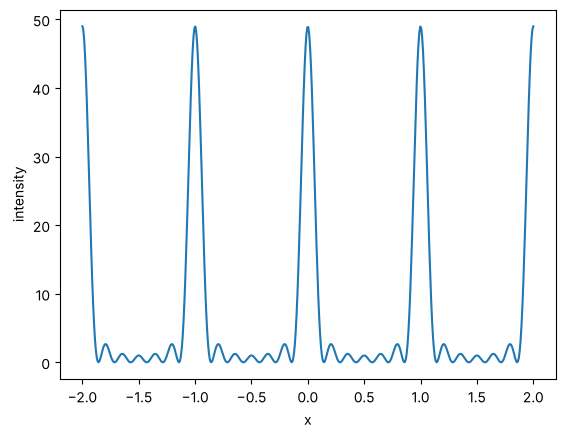

In [2]:
x = np.linspace(-2., 2., 500)
n = 6  # number of diffracting objects
plt.plot(x, np.sin(np.pi*(n+1)*x)**2/np.sin(np.pi*x)**2)
plt.xlabel("x")
plt.ylabel("intensity")
plt.show()

## Exercise 2

Same lines in IPython. The prompt becomes `In [1]:` / `Out [1]:`, results can be reused (`Out[1]+6`), `np.sin?` shows the help, `%history` shows the commands, `save mysavedhistory 1-5` saves them and `%run mysavedhistory` runs them again.

## Exercise 3

`?*` lists all the objects available in IPython, and `object?` gives the documentation of each one. `%psearch np.lin*` does the same with a filter. In a notebook cell the same search can be done with `dir()`, for example the objects of numpy starting with "lin":

In [3]:
print([name for name in dir(np) if name.startswith("lin")])

['linalg', 'linspace']


## Exercise 4

Data: IR spectrum of ethanol (gas) from the NIST webbook, file `64-17-5-IR.jdx`. The peak between 3500 and 3800 cm$^{-1}$ is fitted with a Gaussian and with a Lorentzian:

$$G(x) = a\,e^{-\frac{(x-x_0)^2}{2\sigma^2}}, \quad \mathrm{FWHM} = 2\sqrt{2\ln 2}\,\sigma \qquad\qquad L(x) = \frac{a}{1+\left(\frac{x-x_0}{\Gamma/2}\right)^2}, \quad \mathrm{FWHM} = \Gamma$$

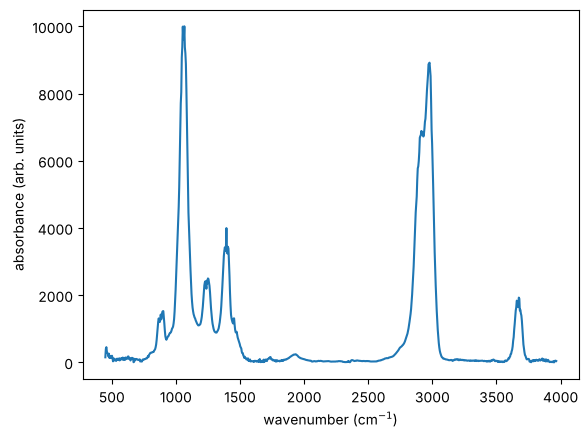

In [4]:
data = np.loadtxt('64-17-5-IR.jdx', unpack=True, skiprows=25, comments='##')
x = []; y = []
for i in range(len(data[0])):
    for j in range(10):
        x.append(data[0][i] + 4*j)
        y.append(data[j+1][i])
x = np.array(x); y = np.array(y)

plt.plot(x, y)
plt.xlabel(r"wavenumber (cm$^{-1}$)")
plt.ylabel("absorbance (arb. units)")
plt.show()

Gaussian:   position 3669.4 cm-1, FWHM 64.7 cm-1, RMS residuals 63
Lorentzian: position 3669.3 cm-1, FWHM 53.2 cm-1, RMS residuals 131


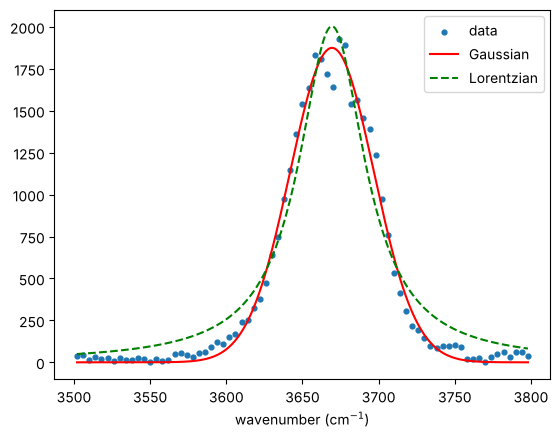

In [5]:
def gaussian(x, a, x0, sigma):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))

def lorentzian(x, a, x0, gamma):
    return a/(1 + ((x-x0)/(gamma/2))**2)

zone = (x >= 3500) & (x < 3800)
xp, yp = x[zone], y[zone]
m = np.argmax(yp)

pg, _ = curve_fit(gaussian, xp, yp, p0=[yp[m], xp[m], 1])
pl, _ = curve_fit(lorentzian, xp, yp, p0=[yp[m], xp[m], 10])
fwhm_g = 2*np.sqrt(2*np.log(2))*abs(pg[2])

rms_g = np.sqrt(np.mean((yp - gaussian(xp, *pg))**2))
rms_l = np.sqrt(np.mean((yp - lorentzian(xp, *pl))**2))
print(f"Gaussian:   position {pg[1]:.1f} cm-1, FWHM {fwhm_g:.1f} cm-1, RMS residuals {rms_g:.0f}")
print(f"Lorentzian: position {pl[1]:.1f} cm-1, FWHM {abs(pl[2]):.1f} cm-1, RMS residuals {rms_l:.0f}")

xf = np.linspace(xp[0], xp[-1], 500)
plt.scatter(xp, yp, s=12, label='data')
plt.plot(xf, gaussian(xf, *pg), 'r', label='Gaussian')
plt.plot(xf, lorentzian(xf, *pl), 'g--', label='Lorentzian')
plt.xlabel(r"wavenumber (cm$^{-1}$)")
plt.legend()
plt.show()

Both give the same position (O-H stretching, about 3669 cm$^{-1}$), but the Gaussian fits better: the Lorentzian tails are too wide.

Physically, a single line broadened by the lifetime of the excited state or by collisions is Lorentzian. Here the band is the envelope of many unresolved rotational lines of the gas, which adds up to a shape closer to a Gaussian. So the Lorentzian is the right shape for one line, the Gaussian is better for this band.

## Exercise 5

The two strongest peaks between 2500 and 3250 cm$^{-1}$ (C-H stretching) overlap, so they are fitted together with a sum of two functions plus a constant background.

Gaussians:   peak 1 at 2915.9 cm-1, FWHM 116.3 | peak 2 at 2984.0 cm-1, FWHM 59.4 | RMS 136
Lorentzians: peak 1 at 2906.8 cm-1, FWHM 94.2 | peak 2 at 2977.1 cm-1, FWHM 56.8 | RMS 268
O-H peak of exercise 4: FWHM 64.7 cm-1


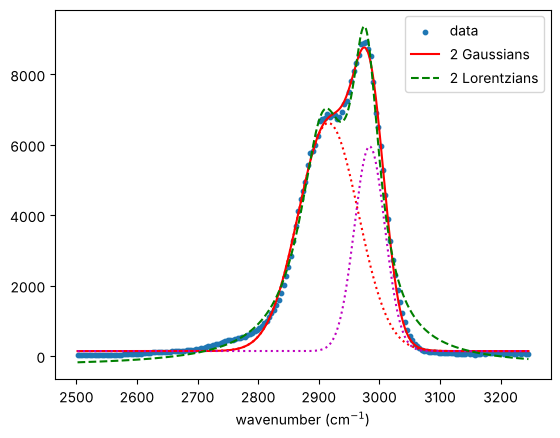

In [6]:
def two_gaussians(x, a1, x1, s1, a2, x2, s2, b):
    return gaussian(x, a1, x1, s1) + gaussian(x, a2, x2, s2) + b

def two_lorentzians(x, a1, x1, g1, a2, x2, g2, b):
    return lorentzian(x, a1, x1, g1) + lorentzian(x, a2, x2, g2) + b

zone = (x >= 2500) & (x < 3250)
xp2, yp2 = x[zone], y[zone]

p_g, _ = curve_fit(two_gaussians, xp2, yp2, p0=[6800, 2914, 20, 8900, 2978, 20, 0])
p_l, _ = curve_fit(two_lorentzians, xp2, yp2, p0=[6800, 2914, 40, 8900, 2978, 40, 0])

k = 2*np.sqrt(2*np.log(2))
print(f"Gaussians:   peak 1 at {p_g[1]:.1f} cm-1, FWHM {k*abs(p_g[2]):.1f} | peak 2 at {p_g[4]:.1f} cm-1, FWHM {k*abs(p_g[5]):.1f}"
      f" | RMS {np.sqrt(np.mean((yp2 - two_gaussians(xp2, *p_g))**2)):.0f}")
print(f"Lorentzians: peak 1 at {p_l[1]:.1f} cm-1, FWHM {abs(p_l[2]):.1f} | peak 2 at {p_l[4]:.1f} cm-1, FWHM {abs(p_l[5]):.1f}"
      f" | RMS {np.sqrt(np.mean((yp2 - two_lorentzians(xp2, *p_l))**2)):.0f}")
print(f"O-H peak of exercise 4: FWHM {fwhm_g:.1f} cm-1")

xf = np.linspace(xp2[0], xp2[-1], 1000)
plt.scatter(xp2, yp2, s=10, label='data')
plt.plot(xf, two_gaussians(xf, *p_g), 'r', label='2 Gaussians')
plt.plot(xf, gaussian(xf, *p_g[0:3]) + p_g[6], 'r:')
plt.plot(xf, gaussian(xf, *p_g[3:6]) + p_g[6], 'm:')
plt.plot(xf, two_lorentzians(xf, *p_l), 'g--', label='2 Lorentzians')
plt.xlabel(r"wavenumber (cm$^{-1}$)")
plt.legend()
plt.show()

Two Gaussians fit better again. The peak at about 2984 cm$^{-1}$ has a width close to the O-H peak (about 60 cm$^{-1}$), while the one at about 2916 cm$^{-1}$ is about twice as wide, because several C-H modes (CH$_3$, CH$_2$) are merged in it.

## Exercise 6

Random points in the unit square: the fraction below $\sqrt{1-x^2}$ estimates the area, $\pi/4 \approx 0.7854$.

In [7]:
def fn(t):
    return np.sqrt(1 - t**2)

rng = np.random.default_rng()
for i in range(1, 8):
    n = 10**i
    t = rng.random(n)
    u = rng.random(n)
    I = np.sum(u <= fn(t))/n
    print(f"n = {n:>9d}   I = {I:.6f}   error = {abs(I - np.pi/4):.1e}")
print(f"theory: pi/4 = {np.pi/4:.6f}")

n =        10   I = 0.900000   error = 1.1e-01
n =       100   I = 0.810000   error = 2.5e-02
n =      1000   I = 0.769000   error = 1.6e-02
n =     10000   I = 0.787200   error = 1.8e-03
n =    100000   I = 0.785270   error = 1.3e-04


n =   1000000   I = 0.785798   error = 4.0e-04


n =  10000000   I = 0.785523   error = 1.2e-04
theory: pi/4 = 0.785398


The result tends to $\pi/4$, with an error decreasing like $1/\sqrt{n}$.

## Exercise 7

In [8]:
result = integrate.quad(fn, 0, 1)
print(result)
print("4 x integral =", 4*result[0])
print("pi           =", np.pi)

(0.7853981633974481, 8.833911380179416e-11)
4 x integral = 3.1415926535897922
pi           = 3.141592653589793


`quad` gives $\pi/4$ to machine precision, so $4\int_0^1\sqrt{1-x^2}\,dx = \pi$ (area of a quarter disc of radius 1).

## Exercise 8

max |derivative - cos| = 5.4940496596600497e-11


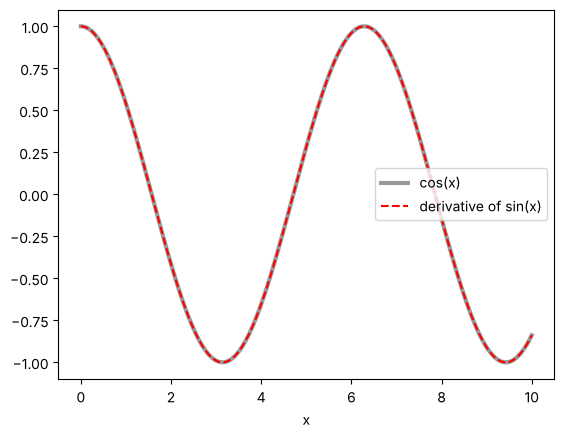

In [9]:
def derivative(f, x, h=1e-5):
    return (f(x+h) - f(x-h))/(2*h)

x = np.linspace(0, 10, 1000)
d = derivative(np.sin, x)
print("max |derivative - cos| =", np.max(np.abs(d - np.cos(x))))

plt.plot(x, np.cos(x), 'k', lw=3, alpha=0.4, label='cos(x)')
plt.plot(x, d, 'r--', label='derivative of sin(x)')
plt.xlabel('x')
plt.legend()
plt.show()

The numerical derivative of $\sin(x)$ is on top of $\cos(x)$.

## Exercise 9

Two masses $m$, each attached to a wall by a spring $k$ and coupled by a spring $k_c$:
$$m\ddot x_1 = -k x_1 - k_c (x_1 - x_2), \qquad m\ddot x_2 = -k x_2 - k_c (x_2 - x_1)$$
Mass 1 starts at $x_1 = 1$, mass 2 at rest at 0, no initial velocity.

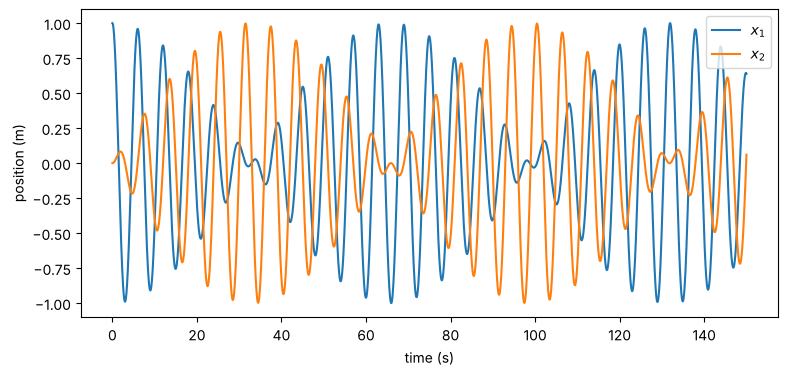

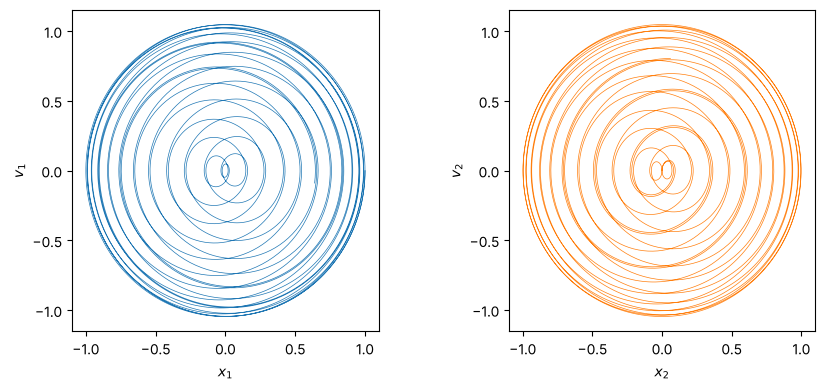

normal modes: w1 = 1.000 rad/s, w2 = 1.095 rad/s, exchange period 2pi/(w2-w1) = 65.8 s


In [10]:
m, k, kc = 1.0, 1.0, 0.1

def deriv(Y, t):
    x1, v1, x2, v2 = Y
    a1 = (-k*x1 - kc*(x1 - x2))/m
    a2 = (-k*x2 - kc*(x2 - x1))/m
    return [v1, a1, v2, a2]

Y0 = [1.0, 0.0, 0.0, 0.0]
t = np.linspace(0, 150, 5000)
res = odeint(deriv, Y0, t)
x1, v1, x2, v2 = res.T

plt.figure(figsize=(9, 4))
plt.plot(t, x1, label='$x_1$')
plt.plot(t, x2, label='$x_2$')
plt.xlabel('time (s)')
plt.ylabel('position (m)')
plt.legend()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.plot(x1, v1, lw=0.5); ax1.set_xlabel('$x_1$'); ax1.set_ylabel('$v_1$')
ax2.plot(x2, v2, lw=0.5, color='C1'); ax2.set_xlabel('$x_2$'); ax2.set_ylabel('$v_2$')
for ax in (ax1, ax2):
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

w1, w2 = np.sqrt(k/m), np.sqrt((k + 2*kc)/m)
print(f"normal modes: w1 = {w1:.3f} rad/s, w2 = {w2:.3f} rad/s, exchange period 2pi/(w2-w1) = {2*np.pi/(w2-w1):.1f} s")

The energy goes back and forth between the two masses (beats), with the period $2\pi/(\omega_2-\omega_1)$ of the two normal modes. In the phase portraits the radius grows and shrinks with the energy of each mass, so the trajectory fills a disc instead of a single ellipse.

## Exercise 10

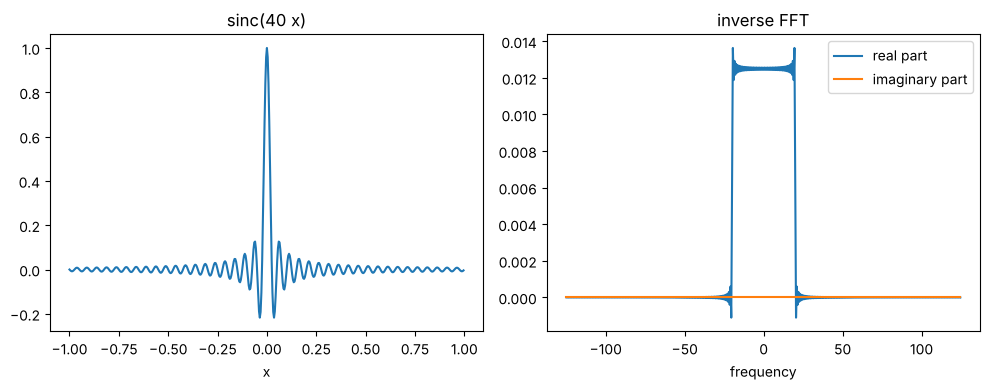

In [11]:
N = 500
x = np.linspace(-1, 1, N, endpoint=False)
dx = x[1] - x[0]
a = 40
s = np.sinc(a*x)

S = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(s)))
f = np.fft.fftshift(np.fft.fftfreq(N, d=dx))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(x, s)
ax1.set_xlabel('x'); ax1.set_title('sinc(40 x)')
ax2.plot(f, S.real, label='real part')
ax2.plot(f, S.imag, label='imaginary part')
ax2.set_xlabel('frequency'); ax2.set_title('inverse FFT')
ax2.legend()
plt.tight_layout()
plt.show()

The inverse Fourier transform of a cardinal sine is a **rectangle function**: constant between $-a/2$ and $a/2$, zero outside, with no imaginary part since the sinc is even. The small oscillations at the edges come from cutting the sinc at $x=\pm1$.